# Week 06｜PDF → 可检查的结构化数据
**三类文档 · 成功表格 → 失败顺序 → 表示差异｜约 4 分钟**

`固定 PDF → 文字 / OCR → 版面与表格 → Markdown / JSON → 人工核验`

[配套讲稿](meeting-notes.md) · [完整报告](report.md) · [课程要求](https://multimodal-vision-ai.github.io/multimodal-document-ai-learning-center/learning/00_12_Week_Bootcamp/#week-6docling-pipeline)

图片已嵌入，代码输出已保存；本 Notebook 仅读取已完成实验，不运行解析模型。

In [1]:
# 只读准备；隐藏的是路径定位和哈希校验，展示代码在各案例下方。
import csv
import hashlib
import json
from pathlib import Path
from IPython.display import Markdown, display

for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / 'week06/configs/baseline.json').is_file():
        ROOT = parent
        break
else:
    raise FileNotFoundError('请在完整 multimodal-ai-bootcamp 仓库中打开 Notebook。')

WEEK = ROOT / 'week06'
RUN = WEEK / 'runs/baseline-20261105T152012-076969'
meta = json.loads((RUN / 'run-metadata.json').read_text())
assert meta['status'] == 'completed'
expected = {item['file']: item['sha256'] for doc in meta['documents'] for item in doc['output_files']}

def original(relative):
    data = (RUN / relative).read_bytes()
    assert hashlib.sha256(data).hexdigest() == expected[relative], relative
    return data.decode('utf-8')

table_doc = json.loads(original('complex_table/document.json'))
digital_md = original('digital_pdf/document.md')
with (WEEK / 'reports/quality-review.csv').open(newline='') as stream:
    review = list(csv.DictReader(stream))
assert len(review) == 10 and all('待核验' not in row['status'] for row in review)

def show_table(headers, rows):
    def clean(value):
        return str(value).replace('|', '\|').replace('\n', ' ')
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(clean, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

print('三文档历史运行已定位；案例原始 JSON/Markdown 哈希一致；10 项人工核验已归档。')

三文档历史运行已定位；案例原始 JSON/Markdown 哈希一致；10 项人工核验已归档。


## 1．实验入口与固定条件

在**仓库根目录**运行的实验命令：

```bash
.venv-week06/bin/python week06/scripts/run_pipeline.py
```

作用：用第六周环境依次解析三份 PDF，保存 Markdown/JSON、配置快照、日志、耗时和退出码。**本人已执行；例会不必重跑。**

In [2]:
config = meta['config']
print(f"Docling {config['expected_packages']['docling']}｜CPU / {config['num_threads']} 线程｜中文 OCR｜表格 {config['table_mode']}｜公式增强关闭")
names = {'digital_pdf': '数字 PDF', 'scanned_pdf': '扫描件', 'complex_table': '复杂表格'}
show_table(['输入', '耗时（秒）', '退出码'],
           [(names[d['id']], d['elapsed_seconds'], d['exit_code']) for d in meta['documents']])
print('耗时包含模型加载；exit=0 只表示执行成功。')

Docling 2.145.0｜CPU / 2 线程｜中文 OCR｜表格 accurate｜公式增强关闭


| 输入 | 耗时（秒） | 退出码 |
| --- | --- | --- |
| 数字 PDF | 18.987 | 0 |
| 扫描件 | 92.008 | 0 |
| 复杂表格 | 26.4093 | 0 |

耗时包含模型加载；exit=0 只表示执行成功。


## 2．成功案例：12、60 的归属能被检查

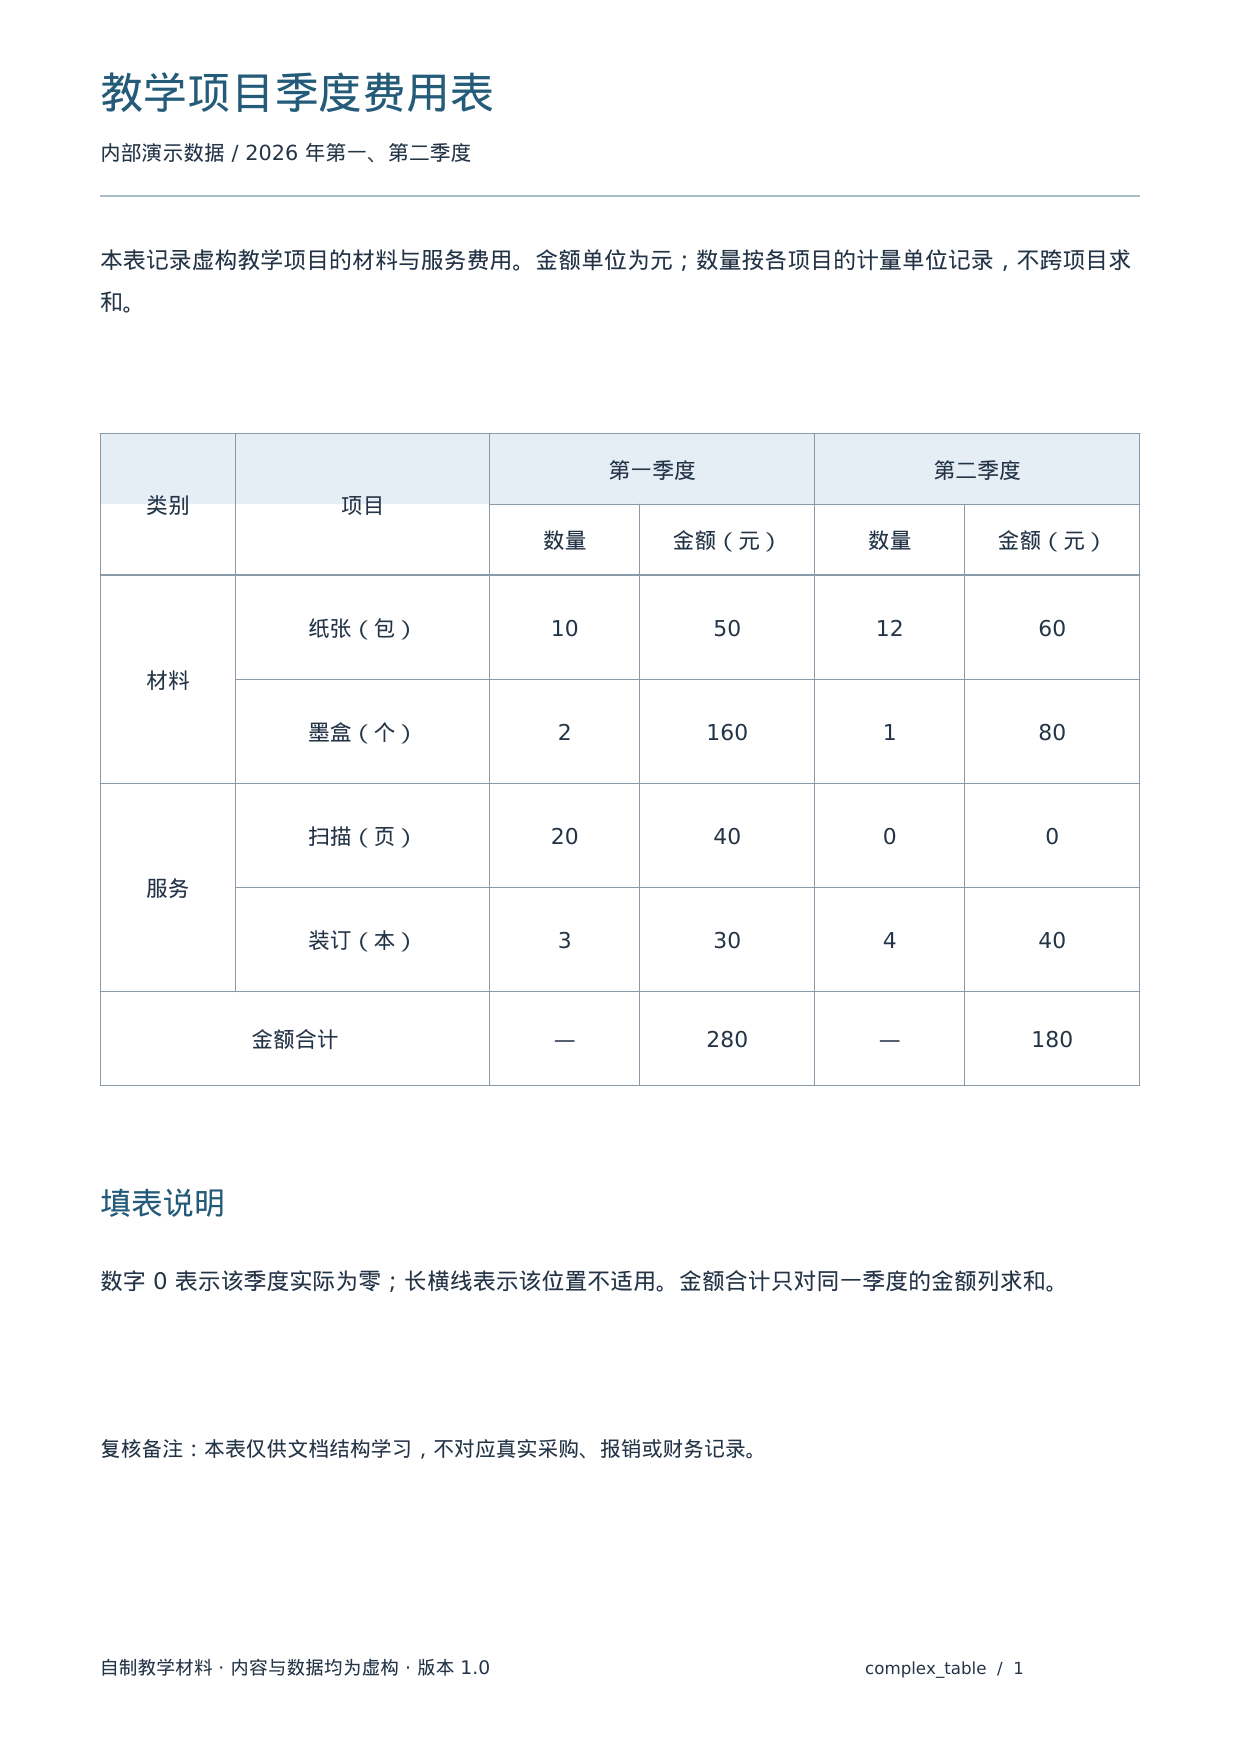

**目标：确认“纸张—第二季度—数量 12 / 金额 60”，而非只找到两个数字。**

In [3]:
table = table_doc['tables'][0]['data']
print(f"JSON 网格：{table['num_rows']} 行 × {table['num_cols']} 列；索引从 0 开始。")
selected = [table['table_cells'][i] for i in [0, 2, 3, 9, 12, 13]]
show_table(['文字', '起始行', '起始列', '跨行', '跨列'],
           [(c['text'], c['start_row_offset_idx'], c['start_col_offset_idx'], c['row_span'], c['col_span']) for c in selected])

JSON 网格：7 行 × 6 列；索引从 0 开始。


| 文字 | 起始行 | 起始列 | 跨行 | 跨列 |
| --- | --- | --- | --- | --- |
| 类别 | 0 | 0 | 2 | 1 |
| 第一季度 | 0 | 2 | 1 | 2 |
| 第二季度 | 0 | 4 | 1 | 2 |
| 纸张（包） | 2 | 1 | 1 | 1 |
| 12 | 2 | 4 | 1 | 1 |
| 60 | 2 | 5 | 1 | 1 |

## 3．失败案例：文字在，逻辑顺序仍可能错

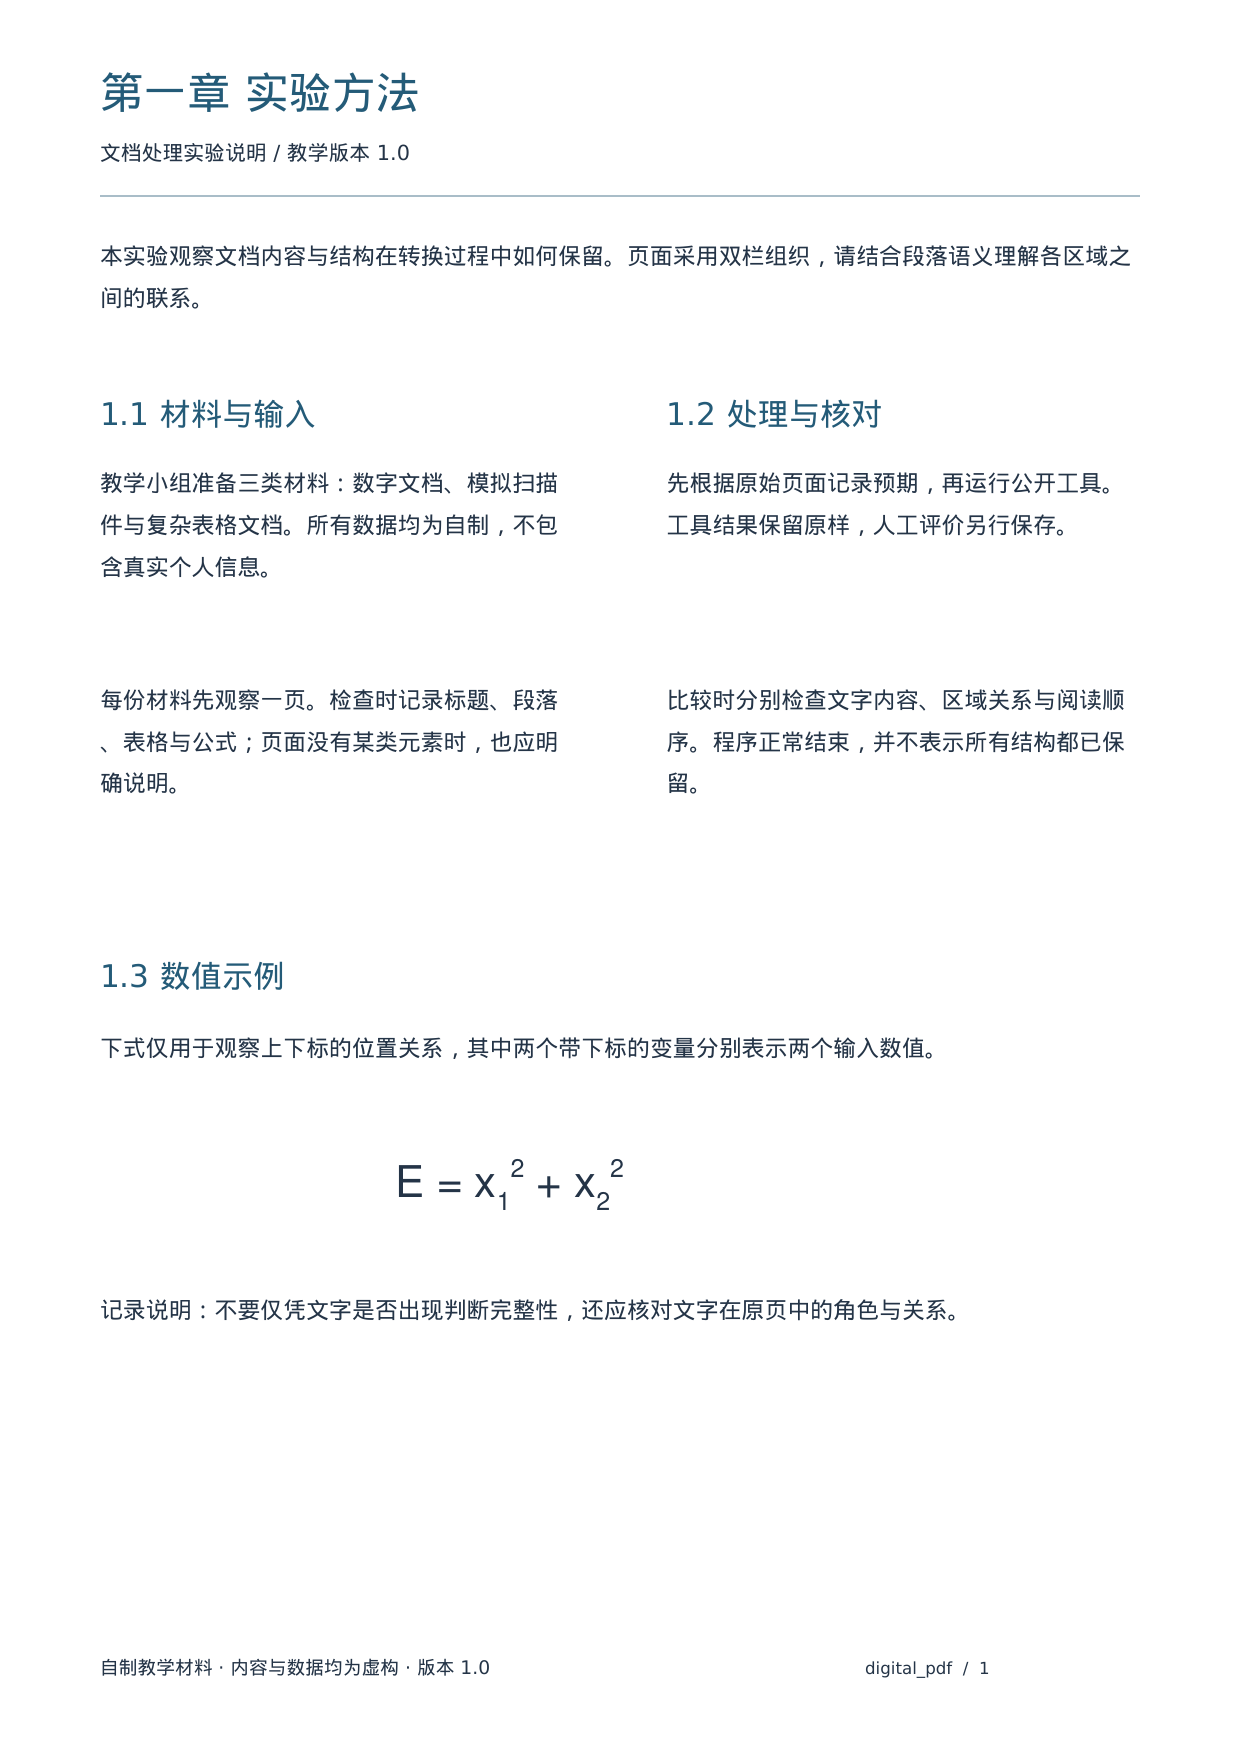

原页预期 **1.1 → 1.2 → 1.3**。同时检查标题层级和公式；本轮未开启公式增强。

In [4]:
headings = [line for line in digital_md.splitlines() if line.startswith('#')]
print('原始 Markdown 标题（保持导出顺序）：')
print('\n'.join(headings))
print('公式区域原始导出：', next(line for line in digital_md.splitlines() if '<!-- image -->' in line))

原始 Markdown 标题（保持导出顺序）：
## 第一章 实验方法
## 1.1 材料与输入
## 1.3 数值示例
## 1.2 处理与核对
公式区域原始导出： <!-- image -->


## 4．表示探索：Markdown 易读，JSON 可查结构

本人选择“表示”方向，比较同一次解析的两种导出。

**Markdown 未显示页脚，JSON 仍保留 → 问题发生在导出范围。** 本轮默认 Markdown 只包含正文 `body` 层，页脚属于 `furniture` 层。

In [5]:
footers = [item for item in table_doc['texts'] if item['label'] == 'page_footer']
show_table(['JSON 标签', '内容层', '原始页脚文字'],
           [(item['label'], item['content_layer'], item['text']) for item in footers])
print('JSON 明确表示关系，但也可能保留错误顺序；更换文件格式不会自动修正解析错误。')

| JSON 标签 | 内容层 | 原始页脚文字 |
| --- | --- | --- |
| page_footer | furniture | 自制教学材料 · 内容与数据均为虚构 · 版本 1.0 |
| page_footer | furniture | complex_table / 1 |

JSON 明确表示关系，但也可能保留错误顺序；更换文件格式不会自动修正解析错误。


## 5．结论、限制与下一步

- **10 项核验**：6 正确、2 部分正确、1 顺序错误、1 公式结构未表达；检查相互关联，不换算总体准确率。
- **收获**：数值对应要看行列与合并关系；执行成功、结构正确、导出完整要分别判断。
- **限制**：三张简化自制教学页；未验证全新机器复现、公式增强对照或下游效果。
- **Week 7 首先做**：固定测试集、来源与划分，确定 baseline 主指标及错误切片。

**讨论：怎样分别评价“结构识别错误”和“导出未显示”？**

本人完成运行与内容核验；Codex根据证据整理Notebook及讲稿，部分概念经提示后确认。[核对表](quality-review.csv) · [复习材料](../docs/core-knowledge.md)